In [9]:
# Run once if packages are missing, then restart the kernel if requested.
%pip install pandas numpy scikit-learn matplotlib

Note: you may need to restart the kernel to use updated packages.


In [10]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

DATA_PATH = Path('sample_monthly_sales.csv')
df = pd.read_csv(DATA_PATH, dtype={'item_code': str, 'warehouse': str})
df['month'] = pd.to_datetime(df['month'], errors='raise')
print('Rows:', len(df))
display(df.head(10))

Rows: 960


,month,item_code,item_name,warehouse,quantity
0,2022-01-01,ITEM001,Brake Pad,Bangalore,86
1,2022-02-01,ITEM001,Brake Pad,Bangalore,85
2,2022-03-01,ITEM001,Brake Pad,Bangalore,108
3,2022-04-01,ITEM001,Brake Pad,Bangalore,113
4,2022-05-01,ITEM001,Brake Pad,Bangalore,84
5,2022-06-01,ITEM001,Brake Pad,Bangalore,84
6,2022-07-01,ITEM001,Brake Pad,Bangalore,88
7,2022-08-01,ITEM001,Brake Pad,Bangalore,75
8,2022-09-01,ITEM001,Brake Pad,Bangalore,71
9,2022-10-01,ITEM001,Brake Pad,Bangalore,63


In [11]:
keys = ['item_code', 'warehouse']
required = ['month', 'item_code', 'item_name', 'warehouse', 'quantity']
assert set(required).issubset(df.columns), 'Required columns are missing.'
assert not df[required].isna().any().any(), 'Missing values found.'
df['quantity'] = pd.to_numeric(df['quantity'], errors='raise')
assert np.isfinite(df['quantity']).all() and (df['quantity'] >= 0).all(), 'Quantity must be finite and non-negative.'
assert df['month'].dt.is_month_start.all(), 'Use month-start dates.'
assert not df.duplicated(keys + ['month']).any(), 'Duplicate item/warehouse/month rows.'
for key, group in df.groupby(keys):
    expected = pd.date_range(df['month'].min(), df['month'].max(), freq='MS')
    assert group['month'].sort_values().tolist() == expected.tolist(), f'Incomplete calendar: {key}'
assert df['month'].nunique() >= 24, 'Provide at least 24 complete months.'
df = df.sort_values(keys + ['month']).reset_index(drop=True)
print('Validation passed.')

Validation passed.


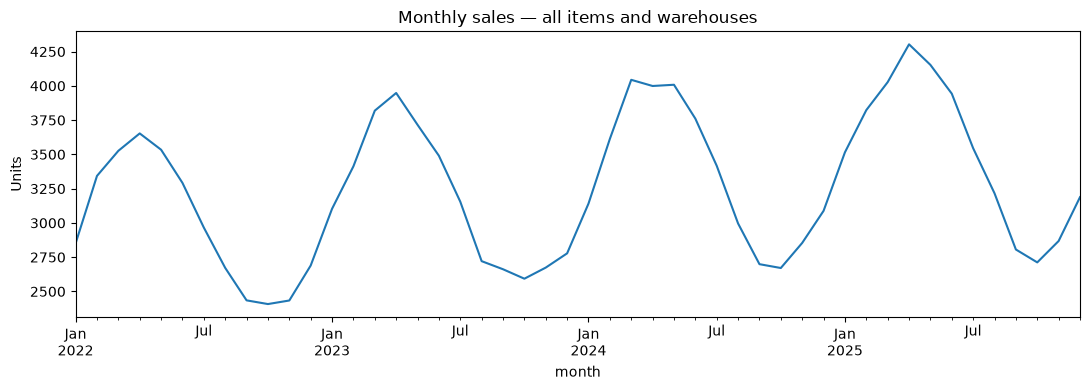

In [12]:
monthly_total = df.groupby('month')['quantity'].sum()
monthly_total.plot(figsize=(11, 4), title='Monthly sales — all items and warehouses', ylabel='Units')
plt.tight_layout()
plt.show()

## 2. Create features without using future sales
Lag 1 is last month's quantity, lag 3 is three months ago and lag 12 is the same month last year. The rolling average is shifted first, so it never includes the target month's quantity.

In [13]:
def make_features(data):
    out = data.sort_values(keys + ['month']).copy()
    grouped = out.groupby(keys)['quantity']
    for lag in [1, 2, 3, 12]:
        out[f'lag_{lag}'] = grouped.shift(lag)
    out['rolling_3'] = grouped.transform(lambda s: s.shift(1).rolling(3).mean())
    out['month_sin'] = np.sin(2 * np.pi * out['month'].dt.month / 12)
    out['month_cos'] = np.cos(2 * np.pi * out['month'].dt.month / 12)
    return out

numeric = ['lag_1', 'lag_2', 'lag_3', 'lag_12', 'rolling_3', 'month_sin', 'month_cos']
features = keys + numeric
featured = make_features(df).dropna(subset=numeric).copy()
display(featured[features + ['month', 'quantity']].head())

,item_code,warehouse,lag_1,lag_2,lag_3,lag_12,rolling_3,month_sin,month_cos,month,quantity
12,ITEM001,Bangalore,84.0,77.0,63.0,86.0,74.666667,0.500000,8.660254e-01,2023-01-01,90
13,ITEM001,Bangalore,90.0,84.0,77.0,85.0,83.666667,0.866025,5.000000e-01,2023-02-01,109
14,ITEM001,Bangalore,109.0,90.0,84.0,108.0,94.333333,1.000000,6.123234e-17,2023-03-01,112
15,ITEM001,Bangalore,112.0,109.0,90.0,113.0,103.666667,0.866025,-5.000000e-01,2023-04-01,102
16,ITEM001,Bangalore,102.0,112.0,109.0,84.0,107.666667,0.500000,-8.660254e-01,2023-05-01,112


In [14]:
test_months = sorted(featured['month'].unique())[-6:]
cutoff = pd.Timestamp(test_months[0])
train = featured[featured['month'] < cutoff]
test = featured[featured['month'] >= cutoff].copy()
preprocess = ColumnTransformer([
    ('categories', OneHotEncoder(handle_unknown='ignore'), keys),
    ('numbers', 'passthrough', numeric)
])
model = Pipeline([
    ('preprocess', preprocess),
    ('regressor', RandomForestRegressor(n_estimators=200, min_samples_leaf=2, random_state=42, n_jobs=-1))
])
model.fit(train[features], train['quantity'])
test['prediction'] = model.predict(test[features])
test['baseline'] = test['rolling_3']
print('Training:', train['month'].min().date(), 'to', train['month'].max().date())
print('Testing:', test['month'].min().date(), 'to', test['month'].max().date())

Training: 2023-01-01 to 2025-06-01
Testing: 2025-07-01 to 2025-12-01


Lower error is better. ML is useful only if it beats an appropriate baseline.


,MAE (units),RMSE (units),WAPE (%)
Random Forest,16.28,22.09,10.66
Last 3 months average,26.14,33.63,17.11


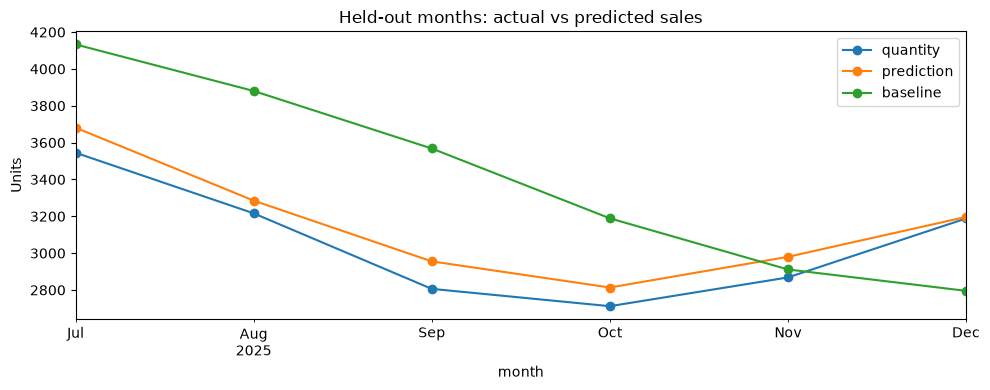

In [15]:
def scores(actual, predicted):
    denominator = np.abs(actual).sum()
    return {
        'MAE (units)': mean_absolute_error(actual, predicted),
        'RMSE (units)': np.sqrt(mean_squared_error(actual, predicted)),
        'WAPE (%)': 100 * np.abs(actual - predicted).sum() / denominator if denominator else np.nan
    }
metrics = pd.DataFrame({
    'Random Forest': scores(test['quantity'], test['prediction']),
    'Last 3 months average': scores(test['quantity'], test['baseline'])
}).T
print('Lower error is better. ML is useful only if it beats an appropriate baseline.')
display(metrics.round(2))
test.groupby('month')[['quantity', 'prediction', 'baseline']].sum().plot(figsize=(10, 4), marker='o', ylabel='Units', title='Held-out months: actual vs predicted sales')
plt.tight_layout()
plt.show()

In [16]:
model.fit(featured[features], featured['quantity'])
next_month = df['month'].max() + pd.offsets.MonthBegin(1)
future = df.groupby(keys).tail(1)[['item_code', 'item_name', 'warehouse']].copy()
future['month'] = next_month
future['quantity'] = np.nan
combined = pd.concat([df, future], ignore_index=True)
future_features = make_features(combined)
future_features = future_features[future_features['month'] == next_month].copy()
assert not future_features[numeric].isna().any().any()
forecast = future_features[['month', 'item_code', 'item_name', 'warehouse']].copy()
forecast['predicted_quantity'] = np.maximum(0, model.predict(future_features[features])).round(0).astype(int)
display(forecast.reset_index(drop=True))
forecast.to_csv('next_month_forecast.csv', index=False)
metrics.to_csv('evaluation_metrics.csv', index_label='model')
print('Saved next_month_forecast.csv and evaluation_metrics.csv')

,month,item_code,item_name,warehouse,predicted_quantity
0,2026-01-01,ITEM001,Brake Pad,Bangalore,102
1,2026-01-01,ITEM001,Brake Pad,Rasipuram,58
2,2026-01-01,ITEM002,Engine Oil,Bangalore,128
3,2026-01-01,ITEM002,Engine Oil,Rasipuram,90
4,2026-01-01,ITEM003,Air Filter,Bangalore,144
5,2026-01-01,ITEM003,Air Filter,Rasipuram,97
6,2026-01-01,ITEM004,Spark Plug,Bangalore,188
7,2026-01-01,ITEM004,Spark Plug,Rasipuram,124
8,2026-01-01,ITEM005,Clutch Cable,Bangalore,185
9,2026-01-01,ITEM005,Clutch Cable,Rasipuram,152


Saved next_month_forecast.csv and evaluation_metrics.csv
